# 02b — Validation Analizi: Popularity ve Item-kNN (`pop_weight=0` vs `pop_weight=0.01`)

## 0. Kurulum ve Veri Yükleme (Yalnızca Train ve Validation)

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis_utils import (
    N_CF_KNOWN_ITEMS,
    build_target_popularity_buckets,
    compute_subset_metrics,
    evaluate_with_user_records,
    make_random_score_fn,
    measure_catalog_coverage_topk,
)
from src.data_loader import N_ITEMS, N_USERS, load_data
from src.evaluation import K, TIE_BREAK_SEED, evaluate
from src.models.item_knn import ItemKNNModel
from src.models.popularity import PopularityModel

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 140)

data = load_data(str(PROJECT_ROOT / "data"))
interaction_matrix = data["interaction_matrix"]
seen_matrix = data["seen_matrix"]
val_candidates = data["val_candidates"]
cold_items = data["cold_items"]
user_activity = data["user_activity"]

item_pop = np.asarray(interaction_matrix.sum(axis=0)).ravel()

pop_model = PopularityModel.load(str(PROJECT_ROOT / "saved_models" / "popularity.pkl"))
knn_pw001 = ItemKNNModel.load(str(PROJECT_ROOT / "saved_models" / "itemknn"))

# pop_weight skor zamanında (_all_scores) uygulandığı için W/R yeniden yüklenip bellekte pop_weight=0.0 yapılır
knn_pw0 = ItemKNNModel.load(str(PROJECT_ROOT / "saved_models" / "itemknn"))
knn_pw0.pop_weight = 0.0

print(f"PopularityModel : n_users={pop_model.n_users}, n_items={pop_model.n_items}")
print(f"ItemKNN (pw=0.01): {knn_pw001}")
print(f"ItemKNN (pw=0.0) : {knn_pw0}")

VERİ YÜKLENDİ — DOĞRULAMA ÖZETİ
  Etkileşim matrisi şekli  : 94745 x 25610
  Beklenen                 : 94745 x 25610
  Pozitif etkileşim (nnz)  : 504,975
  Beklenen (yaklaşık)      : ~505.000
  Val  label==1 satır      : 75,799  (beklenen: 75.799)
  Test label==1 satır      : 74,021  (beklenen: 74.021)

  SOGUK URUN (iki tanim karsilastirmasi):
    Tanim 1 — train'de HIC gorunmeyen  (KULLANILAN):
      Toplam soguk urun: 84
      Test pozitifinde : 251 satir (kullanici)  |  78 tekil urun
      Beklenen satir   : ~251
    Tanim 2 — train'de label==1 olmayan (referans):
      Toplam soguk urun: 243
      Test pozitifinde : 462 satir (kullanici)  |  184 tekil urun
[PopularityModel] Yuklendi: C:\Users\aslih\Desktop\cf_recommender\saved_models\popularity.pkl  (n_items=25,610, is_fitted=True)


PopularityModel : n_users=94745, n_items=25610
ItemKNN (pw=0.01): ItemKNNModel(k=2000, shrink=100.0, pop_weight=0.01, W_nnz=4829580)
ItemKNN (pw=0.0) : ItemKNNModel(k=2000, shrink=100.0, pop_weight=0.0, W_nnz=4829580)


## Adım 1: Referans Sonuçların Yeniden Üretilmesi ve Doğrulanması (Validation)

In [2]:
random_score_fn = make_random_score_fn(seed=42)

# Mevcut evaluate() ile referans ölçümler
eval_rand = evaluate(random_score_fn, val_candidates, cold_items=cold_items, user_activity=user_activity, verbose=False)
eval_pop = evaluate(pop_model.score, val_candidates, cold_items=cold_items, user_activity=user_activity, verbose=False)
eval_pw0 = evaluate(knn_pw0.score, val_candidates, cold_items=cold_items, user_activity=user_activity, verbose=False)
eval_pw001 = evaluate(knn_pw001.score, val_candidates, cold_items=cold_items, user_activity=user_activity, verbose=False)

# Kova analizi için kullanıcı bazlı kayıt tutan yardımcı fonksiyon ölçümleri
rec_rand = evaluate_with_user_records(random_score_fn, val_candidates, cold_items=cold_items, user_activity=user_activity)
rec_pop = evaluate_with_user_records(pop_model.score, val_candidates, cold_items=cold_items, user_activity=user_activity)
rec_pw0 = evaluate_with_user_records(knn_pw0.score, val_candidates, cold_items=cold_items, user_activity=user_activity)
rec_pw001 = evaluate_with_user_records(knn_pw001.score, val_candidates, cold_items=cold_items, user_activity=user_activity)

ref_checks = [
    ("Popularity", eval_pop, rec_pop, 0.5488, 0.3369),
    ("Item-kNN (k=2000, shrink=100, pw=0)", eval_pw0, rec_pw0, 0.5714, 0.4210),
    ("Item-kNN (k=2000, shrink=100, pw=0.01)", eval_pw001, rec_pw001, 0.6400, 0.4520),
]

step1_rows = []
for name, ev, rc, exp_hr, exp_ndcg in ref_checks:
    hr = ev["overall"]["hit_rate"]
    ndcg = ev["overall"]["ndcg"]
    hr_rc = rc["overall"]["hit_rate"]
    ndcg_rc = rc["overall"]["ndcg"]
    diff_hr_exp = abs(hr - exp_hr)
    diff_ndcg_exp = abs(ndcg - exp_ndcg)
    diff_helper_hr = abs(hr - hr_rc)
    diff_helper_ndcg = abs(ndcg - ndcg_rc)

    assert diff_hr_exp <= 0.001, f"{name} HR@10 tolerans dışı: {hr:.6f} vs {exp_hr}"
    assert diff_ndcg_exp <= 0.001, f"{name} NDCG@10 tolerans dışı: {ndcg:.6f} vs {exp_ndcg}"
    assert diff_helper_hr <= 1e-6, f"{name} helper HR farkı > 1e-6: {diff_helper_hr}"
    assert diff_helper_ndcg <= 1e-6, f"{name} helper NDCG farkı > 1e-6: {diff_helper_ndcg}"

    step1_rows.append({
        "model": name,
        "expected_hr_at_10": exp_hr,
        "obtained_hr_at_10": round(hr, 6),
        "abs_diff_hr": round(diff_hr_exp, 6),
        "expected_ndcg_at_10": exp_ndcg,
        "obtained_ndcg_at_10": round(ndcg, 6),
        "abs_diff_ndcg": round(diff_ndcg_exp, 6),
        "helper_vs_evaluate_diff": max(diff_helper_hr, diff_helper_ndcg),
        "pool_coverage_pct": round(ev["overall"]["coverage_pct"], 2),
        "pool_coverage_n": int(ev["overall"]["coverage_n"]),
    })

# Random modelin evaluate() vs helper kontrolü
assert abs(eval_rand["overall"]["hit_rate"] - rec_rand["overall"]["hit_rate"]) <= 1e-6
step1_rows.insert(0, {
    "model": "Random (seed=42)",
    "expected_hr_at_10": 0.1000,
    "obtained_hr_at_10": round(eval_rand["overall"]["hit_rate"], 6),
    "abs_diff_hr": round(abs(eval_rand["overall"]["hit_rate"] - 0.1000), 6),
    "expected_ndcg_at_10": 0.0455,
    "obtained_ndcg_at_10": round(eval_rand["overall"]["ndcg"], 6),
    "abs_diff_ndcg": round(abs(eval_rand["overall"]["ndcg"] - 0.0455), 6),
    "helper_vs_evaluate_diff": abs(eval_rand["overall"]["hit_rate"] - rec_rand["overall"]["hit_rate"]),
    "pool_coverage_pct": round(eval_rand["overall"]["coverage_pct"], 2),
    "pool_coverage_n": int(eval_rand["overall"]["coverage_n"]),
})

df_step1 = pd.DataFrame(step1_rows)
print("ADIM 1 — REFERANS SONUÇ KONTROL TABLOSU (VALIDATION, N = 75.799):")
display(df_step1)

ADIM 1 — REFERANS SONUÇ KONTROL TABLOSU (VALIDATION, N = 75.799):


,model,expected_hr_at_10,obtained_hr_at_10,abs_diff_hr,expected_ndcg_at_10,obtained_ndcg_at_10,abs_diff_ndcg,helper_vs_evaluate_diff,pool_coverage_pct,pool_coverage_n
0,Random (seed=42),0.1000,0.101136,0.001136,0.0455,0.045602,0.000102,0.0,99.67,25526
1,Popularity,0.5488,0.548780,0.000020,0.3369,0.336911,0.000011,0.0,19.84,5082
2,"Item-kNN (k=2000, shrink=100, pw=0)",0.5714,0.571366,0.000034,0.4210,0.421030,0.000030,0.0,99.67,25526
3,"Item-kNN (k=2000, shrink=100, pw=0.01)",0.6400,0.640022,0.000022,0.4520,0.452027,0.000027,0.0,91.04,23316


## Adım 2: Hedef Ürünün Popülerlik Kovasına Göre HR@10 ve NDCG@10

In [3]:
df_val_targets, bucket_summaries = build_target_popularity_buckets(val_candidates, item_pop)

df_bucket_info = pd.DataFrame([
    {
        "bucket": b["bucket"],
        "n_users": b["n_users"],
        "user_share_pct": round(b["user_share_pct"], 2),
        "n_unique_target_items": b["n_unique_target_items"],
        "min_pos_count": b["min_pop"],
        "max_pos_count": b["max_pop"],
        "median_pos_count": round(b["median_pop"], 1),
        "mean_pos_count": round(b["mean_pop"], 2),
    }
    for b in bucket_summaries
])
print("VAL HEDEF ÜRÜN POPÜLERLİK KOVALARI TANIM TABLOSU:")
display(df_bucket_info)

models_for_buckets = [
    ("Random (seed=42)", rec_rand, eval_rand),
    ("Popularity", rec_pop, eval_pop),
    ("Item-kNN (pw=0)", rec_pw0, eval_pw0),
    ("Item-kNN (pw=0.01)", rec_pw001, eval_pw001),
]

bucket_metric_rows = []
model_bucket_map = {}

for m_name, m_rec, m_eval in models_for_buckets:
    model_bucket_map[m_name] = {}
    weighted_hits = 0
    weighted_ndcg_sum = 0.0
    total_u = 0

    for b in bucket_summaries:
        b_name = b["bucket"]
        sub_m = compute_subset_metrics(m_rec, b["user_set"], k=K)
        model_bucket_map[m_name][b_name] = sub_m

        weighted_hits += sub_m["hits"]
        weighted_ndcg_sum += sub_m["ndcg"] * sub_m["n_users"]
        total_u += sub_m["n_users"]

        bucket_metric_rows.append({
            "bucket": b_name,
            "n_users": b["n_users"],
            "user_share_pct": round(b["user_share_pct"], 2),
            "min_pos_count": b["min_pop"],
            "max_pos_count": b["max_pop"],
            "model": m_name,
            "hits": sub_m["hits"],
            "hr_at_10": round(sub_m["hit_rate"], 6),
            "ndcg_at_10": round(sub_m["ndcg"], 6),
            "prec_at_10": round(sub_m["precision"], 6),
            "recall_at_10": round(sub_m["recall"], 6),
        })

    reconstructed_hr = weighted_hits / float(total_u)
    reconstructed_ndcg = weighted_ndcg_sum / float(total_u)
    eval_hr = m_eval["overall"]["hit_rate"]
    eval_ndcg = m_eval["overall"]["ndcg"]

    assert abs(reconstructed_hr - eval_hr) <= 1e-6, f"{m_name} kova ağırlıklı HR != evaluate() HR"
    assert abs(reconstructed_ndcg - eval_ndcg) <= 1e-6, f"{m_name} kova ağırlıklı NDCG != evaluate() NDCG"

df_bucket_metrics = pd.DataFrame(bucket_metric_rows)

# Kova x Model özet pivot tabloları
pivot_hr = df_bucket_metrics.pivot(index="bucket", columns="model", values="hr_at_10").loc[
    ["soğuk", "kuyruk", "orta", "baş"],
    ["Random (seed=42)", "Popularity", "Item-kNN (pw=0)", "Item-kNN (pw=0.01)"],
]
pivot_ndcg = df_bucket_metrics.pivot(index="bucket", columns="model", values="ndcg_at_10").loc[
    ["soğuk", "kuyruk", "orta", "baş"],
    ["Random (seed=42)", "Popularity", "Item-kNN (pw=0)", "Item-kNN (pw=0.01)"],
]

print("\nKOVA BAZLI HR@10 TABLOSU:")
display(pivot_hr.round(4))
print("\nKOVA BAZLI NDCG@10 TABLOSU:")
display(pivot_ndcg.round(4))

# Kazanç payı tablosu (Item-kNN pw=0 ve pw=0.01 vs Popularity)
total_gain_hits_pw0 = sum(
    model_bucket_map["Item-kNN (pw=0)"][b["bucket"]]["hits"] - model_bucket_map["Popularity"][b["bucket"]]["hits"]
    for b in bucket_summaries
)
total_gain_hits_pw001 = sum(
    model_bucket_map["Item-kNN (pw=0.01)"][b["bucket"]]["hits"] - model_bucket_map["Popularity"][b["bucket"]]["hits"]
    for b in bucket_summaries
)

gain_rows = []
for b in bucket_summaries:
    b_name = b["bucket"]
    pop_hits = model_bucket_map["Popularity"][b_name]["hits"]
    pw0_hits = model_bucket_map["Item-kNN (pw=0)"][b_name]["hits"]
    pw001_hits = model_bucket_map["Item-kNN (pw=0.01)"][b_name]["hits"]

    d_hits_pw0 = pw0_hits - pop_hits
    d_hits_pw001 = pw001_hits - pop_hits

    d_hr_pw0 = model_bucket_map["Item-kNN (pw=0)"][b_name]["hit_rate"] - model_bucket_map["Popularity"][b_name]["hit_rate"]
    d_hr_pw001 = model_bucket_map["Item-kNN (pw=0.01)"][b_name]["hit_rate"] - model_bucket_map["Popularity"][b_name]["hit_rate"]

    gain_rows.append({
        "bucket": b_name,
        "n_users": b["n_users"],
        "pop_hits": pop_hits,
        "pw0_hits": pw0_hits,
        "pw0_minus_pop_hits": d_hits_pw0,
        "pw0_minus_pop_hr": round(d_hr_pw0, 4),
        "pw0_share_of_net_gain_pct": round((d_hits_pw0 / float(total_gain_hits_pw0)) * 100.0, 2),
        "pw001_hits": pw001_hits,
        "pw001_minus_pop_hits": d_hits_pw001,
        "pw001_minus_pop_hr": round(d_hr_pw001, 4),
        "pw001_share_of_net_gain_pct": round((d_hits_pw001 / float(total_gain_hits_pw001)) * 100.0, 2),
    })

gain_rows.append({
    "bucket": "TOPLAM (Genel)",
    "n_users": len(val_candidates),
    "pop_hits": sum(r["pop_hits"] for r in gain_rows),
    "pw0_hits": sum(r["pw0_hits"] for r in gain_rows),
    "pw0_minus_pop_hits": total_gain_hits_pw0,
    "pw0_minus_pop_hr": round(eval_pw0["overall"]["hit_rate"] - eval_pop["overall"]["hit_rate"], 4),
    "pw0_share_of_net_gain_pct": 100.0,
    "pw001_hits": sum(r["pw001_hits"] for r in gain_rows),
    "pw001_minus_pop_hits": total_gain_hits_pw001,
    "pw001_minus_pop_hr": round(eval_pw001["overall"]["hit_rate"] - eval_pop["overall"]["hit_rate"], 4),
    "pw001_share_of_net_gain_pct": 100.0,
})

df_gain_share = pd.DataFrame(gain_rows)
print("\nPOPULARITY'YE GÖRE HIT KAZANCI VE KAZANÇ PAYI TABLOSU:")
display(df_gain_share)

# CSV kaydı: results/analysis_pop_bucket_val.csv
wide_bucket_rows = []
for i, b in enumerate(bucket_summaries):
    b_name = b["bucket"]
    g_row = gain_rows[i]
    wide_bucket_rows.append({
        "bucket": b_name,
        "n_users": b["n_users"],
        "user_share_pct": round(b["user_share_pct"], 4),
        "n_unique_target_items": b["n_unique_target_items"],
        "min_pos_count": b["min_pop"],
        "max_pos_count": b["max_pop"],
        "median_pos_count": round(b["median_pop"], 2),
        "mean_pos_count": round(b["mean_pop"], 2),
        "random_hr_at_10": round(model_bucket_map["Random (seed=42)"][b_name]["hit_rate"], 6),
        "random_ndcg_at_10": round(model_bucket_map["Random (seed=42)"][b_name]["ndcg"], 6),
        "popularity_hr_at_10": round(model_bucket_map["Popularity"][b_name]["hit_rate"], 6),
        "popularity_ndcg_at_10": round(model_bucket_map["Popularity"][b_name]["ndcg"], 6),
        "itemknn_pw0_hr_at_10": round(model_bucket_map["Item-kNN (pw=0)"][b_name]["hit_rate"], 6),
        "itemknn_pw0_ndcg_at_10": round(model_bucket_map["Item-kNN (pw=0)"][b_name]["ndcg"], 6),
        "itemknn_pw001_hr_at_10": round(model_bucket_map["Item-kNN (pw=0.01)"][b_name]["hit_rate"], 6),
        "itemknn_pw001_ndcg_at_10": round(model_bucket_map["Item-kNN (pw=0.01)"][b_name]["ndcg"], 6),
        "pop_hits": g_row["pop_hits"],
        "pw0_hits": g_row["pw0_hits"],
        "pw0_gain_hits": g_row["pw0_minus_pop_hits"],
        "pw0_gain_share_pct": g_row["pw0_share_of_net_gain_pct"],
        "pw001_hits": g_row["pw001_hits"],
        "pw001_gain_hits": g_row["pw001_minus_pop_hits"],
        "pw001_gain_share_pct": g_row["pw001_share_of_net_gain_pct"],
    })

df_pop_bucket_export = pd.DataFrame(wide_bucket_rows)
pop_bucket_csv_path = PROJECT_ROOT / "results" / "analysis_pop_bucket_val.csv"
df_pop_bucket_export.to_csv(pop_bucket_csv_path, index=False)
print(f"\nKaydedildi: {pop_bucket_csv_path}")

VAL HEDEF ÜRÜN POPÜLERLİK KOVALARI TANIM TABLOSU:


,bucket,n_users,user_share_pct,n_unique_target_items,min_pos_count,max_pos_count,median_pos_count,mean_pos_count
0,soğuk,263,0.35,151,0,0,0.0,0.00
1,kuyruk,25320,33.40,12548,1,23,9.0,9.99
2,orta,25114,33.13,3562,24,111,54.0,58.04
3,baş,25102,33.12,759,112,1901,253.0,386.94



KOVA BAZLI HR@10 TABLOSU:


model,Random (seed=42),Popularity,Item-kNN (pw=0),Item-kNN (pw=0.01)
bucket,,,,
soğuk,0.0646,0.0000,0.0266,0.0000
kuyruk,0.1030,0.0010,0.2884,0.2231
orta,0.0996,0.6558,0.5774,0.7088
baş,0.1012,1.0000,0.8565,0.9985



KOVA BAZLI NDCG@10 TABLOSU:


model,Random (seed=42),Popularity,Item-kNN (pw=0),Item-kNN (pw=0.01)
bucket,,,,
soğuk,0.0273,0.0000,0.0090,0.0000
kuyruk,0.0465,0.0003,0.1917,0.1398
orta,0.0449,0.2492,0.3904,0.4022
baş,0.0455,0.7677,0.6873,0.8216



POPULARITY'YE GÖRE HIT KAZANCI VE KAZANÇ PAYI TABLOSU:


,bucket,n_users,pop_hits,pw0_hits,pw0_minus_pop_hits,pw0_minus_pop_hr,pw0_share_of_net_gain_pct,pw001_hits,pw001_minus_pop_hits,pw001_minus_pop_hr,pw001_share_of_net_gain_pct
0,soğuk,263,0,7,7,0.0266,0.41,0,0,0.0000,0.00
1,kuyruk,25320,26,7302,7276,0.2874,425.00,5649,5623,0.2221,81.30
2,orta,25114,16469,14501,-1968,-0.0784,-114.95,17800,1331,0.0530,19.25
3,baş,25102,25102,21499,-3603,-0.1435,-210.46,25064,-38,-0.0015,-0.55
4,TOPLAM (Genel),75799,41597,43309,1712,0.0226,100.00,48513,6916,0.0912,100.00



Kaydedildi: C:\Users\aslih\Desktop\cf_recommender\results\analysis_pop_bucket_val.csv


### Grafik 1: Popülerlik Kovasına Göre HR@10 ve NDCG@10

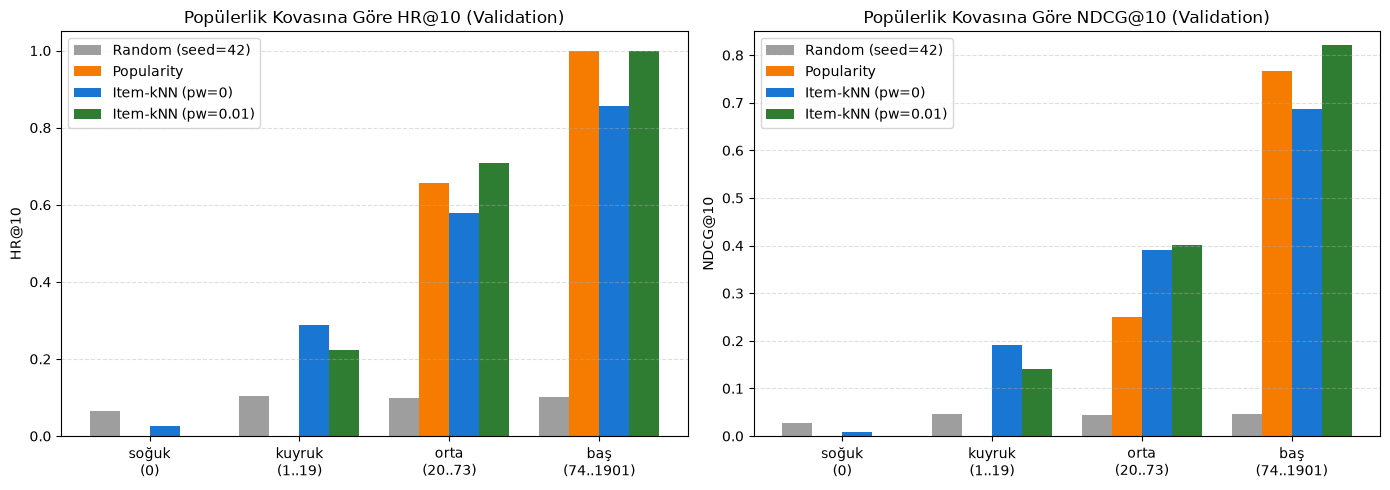

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bucket_labels = ["soğuk\n(0)", "kuyruk\n(1..23)", "orta\n(24..111)", "baş\n(112..1901)"]
x = np.arange(len(bucket_labels))
width = 0.20

model_cols = ["Random (seed=42)", "Popularity", "Item-kNN (pw=0)", "Item-kNN (pw=0.01)"]
colors = ["#9e9e9e", "#f57c00", "#1976d2", "#2e7d32"]

for i, (m_col, col_color) in enumerate(zip(model_cols, colors)):
    hr_vals = pivot_hr[m_col].to_numpy()
    ndcg_vals = pivot_ndcg[m_col].to_numpy()
    offset = (i - 1.5) * width
    axes[0].bar(x + offset, hr_vals, width, label=m_col, color=col_color)
    axes[1].bar(x + offset, ndcg_vals, width, label=m_col, color=col_color)

axes[0].set_title("Popülerlik Kovasına Göre HR@10 (Validation)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(bucket_labels)
axes[0].set_ylabel("HR@10")
axes[0].set_ylim(0, 1.05)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend()

axes[1].set_title("Popülerlik Kovasına Göre NDCG@10 (Validation)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(bucket_labels)
axes[1].set_ylabel("NDCG@10")
axes[1].set_ylim(0, 0.85)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.show()

## Adım 3: Gerçek Katalog Coverage@10 (N = 10.000 Validation Kullanıcısı, `seed=42`, `mode='live'`)

In [5]:
COVERAGE_SAMPLE_SEED = 42
N_COVERAGE_SAMPLE = 10_000

val_user_ids_sorted = sorted(val_candidates.keys())
rng_cov = np.random.default_rng(COVERAGE_SAMPLE_SEED)
sampled_val_uids = rng_cov.choice(val_user_ids_sorted, size=N_COVERAGE_SAMPLE, replace=False).tolist()

cov_pop = measure_catalog_coverage_topk(
    model_name="Popularity",
    recommend_fn=lambda uid: pop_model.recommend_topk(
        uid, interaction_matrix, k=K, exclude_seen=True, seen_matrix=seen_matrix, mode="live"
    ).tolist(),
    sampled_uids=sampled_val_uids,
    item_pop=item_pop,
    pool_coverage_pct=eval_pop["overall"]["coverage_pct"],
    pool_coverage_n=eval_pop["overall"]["coverage_n"],
    k=K,
)

cov_pw0 = measure_catalog_coverage_topk(
    model_name="Item-kNN (pw=0)",
    recommend_fn=lambda uid: [
        item_idx
        for item_idx, _ in knn_pw0.recommend_topk(
            uid, k=K, exclude_seen=True, seen_matrix=seen_matrix, mode="live"
        )
    ],
    sampled_uids=sampled_val_uids,
    item_pop=item_pop,
    pool_coverage_pct=eval_pw0["overall"]["coverage_pct"],
    pool_coverage_n=eval_pw0["overall"]["coverage_n"],
    k=K,
)

cov_pw001 = measure_catalog_coverage_topk(
    model_name="Item-kNN (pw=0.01)",
    recommend_fn=lambda uid: [
        item_idx
        for item_idx, _ in knn_pw001.recommend_topk(
            uid, k=K, exclude_seen=True, seen_matrix=seen_matrix, mode="live"
        )
    ],
    sampled_uids=sampled_val_uids,
    item_pop=item_pop,
    pool_coverage_pct=eval_pw001["overall"]["coverage_pct"],
    pool_coverage_n=eval_pw001["overall"]["coverage_n"],
    k=K,
)

df_catalog_cov = pd.DataFrame([cov_pop, cov_pw0, cov_pw001])
cov_csv_path = PROJECT_ROOT / "results" / "analysis_catalog_coverage_val.csv"
df_catalog_cov.to_csv(cov_csv_path, index=False)

print(f"GERÇEK KATALOG COVERAGE@10 vs HAVUZ COVERAGE@10 (N = {N_COVERAGE_SAMPLE:,} Val Kullanıcısı, seed={COVERAGE_SAMPLE_SEED}):")
display(df_catalog_cov[[
    "model",
    "n_sample_users",
    "unique_rec_items",
    "catalog_cov_25610_pct",
    "catalog_cov_25367_known_pct",
    "pool_coverage_pct",
    "pool_coverage_n",
    "top100_pop_item_share_pct",
    "mean_pop_percentile_rank",
    "elapsed_seconds",
    "peak_rss_mb",
    "tracemalloc_peak_mb",
]].round(4))
print(f"Kaydedildi: {cov_csv_path}")

GERÇEK KATALOG COVERAGE@10 vs HAVUZ COVERAGE@10 (N = 10,000 Val Kullanıcısı, seed=42):


,model,n_sample_users,unique_rec_items,catalog_cov_25610_pct,catalog_cov_25367_known_pct,pool_coverage_pct,pool_coverage_n,top100_pop_item_share_pct,mean_pop_percentile_rank,elapsed_seconds,peak_rss_mb,tracemalloc_peak_mb
0,Popularity,10000,15,0.0586,0.0591,19.8438,5082,100.000,99.9820,15.4487,745.11,4.78
1,Item-kNN (pw=0),10000,13022,50.8473,51.3344,99.6720,25526,28.675,86.0044,21.5982,746.86,4.95
2,Item-kNN (pw=0.01),10000,4272,16.6810,16.8408,91.0426,23316,62.701,97.0620,22.8128,746.95,4.95


Kaydedildi: C:\Users\aslih\Desktop\cf_recommender\results\analysis_catalog_coverage_val.csv


## Adım 4: `pop_weight=0` vs `pop_weight=0.01` Özet Karşılaştırması

In [6]:
summary_rows = [
    # Genel
    {
        "section": "Genel",
        "metric": "HR@10 (Genel, N=75.799)",
        "popularity": round(eval_pop["overall"]["hit_rate"], 4),
        "itemknn_pw0": round(eval_pw0["overall"]["hit_rate"], 4),
        "itemknn_pw001": round(eval_pw001["overall"]["hit_rate"], 4),
        "diff_pw001_minus_pw0": round(eval_pw001["overall"]["hit_rate"] - eval_pw0["overall"]["hit_rate"], 4),
    },
    {
        "section": "Genel",
        "metric": "NDCG@10 (Genel, N=75.799)",
        "popularity": round(eval_pop["overall"]["ndcg"], 4),
        "itemknn_pw0": round(eval_pw0["overall"]["ndcg"], 4),
        "itemknn_pw001": round(eval_pw001["overall"]["ndcg"], 4),
        "diff_pw001_minus_pw0": round(eval_pw001["overall"]["ndcg"] - eval_pw0["overall"]["ndcg"], 4),
    },
    # Aktivite Kırılımı HR@10
    {
        "section": "Aktivite Kırılımı (HR@10)",
        "metric": "Düşük (=3, N=24.415) HR@10",
        "popularity": round(eval_pop["activity"]["low"]["hit_rate"], 4),
        "itemknn_pw0": round(eval_pw0["activity"]["low"]["hit_rate"], 4),
        "itemknn_pw001": round(eval_pw001["activity"]["low"]["hit_rate"], 4),
        "diff_pw001_minus_pw0": round(eval_pw001["activity"]["low"]["hit_rate"] - eval_pw0["activity"]["low"]["hit_rate"], 4),
    },
    {
        "section": "Aktivite Kırılımı (HR@10)",
        "metric": "Orta (4-6, N=30.042) HR@10",
        "popularity": round(eval_pop["activity"]["medium"]["hit_rate"], 4),
        "itemknn_pw0": round(eval_pw0["activity"]["medium"]["hit_rate"], 4),
        "itemknn_pw001": round(eval_pw001["activity"]["medium"]["hit_rate"], 4),
        "diff_pw001_minus_pw0": round(eval_pw001["activity"]["medium"]["hit_rate"] - eval_pw0["activity"]["medium"]["hit_rate"], 4),
    },
    {
        "section": "Aktivite Kırılımı (HR@10)",
        "metric": "Yüksek (7+, N=21.342) HR@10",
        "popularity": round(eval_pop["activity"]["high"]["hit_rate"], 4),
        "itemknn_pw0": round(eval_pw0["activity"]["high"]["hit_rate"], 4),
        "itemknn_pw001": round(eval_pw001["activity"]["high"]["hit_rate"], 4),
        "diff_pw001_minus_pw0": round(eval_pw001["activity"]["high"]["hit_rate"] - eval_pw0["activity"]["high"]["hit_rate"], 4),
    },
    # Aktivite Kırılımı NDCG@10
    {
        "section": "Aktivite Kırılımı (NDCG@10)",
        "metric": "Düşük (=3, N=24.415) NDCG@10",
        "popularity": round(eval_pop["activity"]["low"]["ndcg"], 4),
        "itemknn_pw0": round(eval_pw0["activity"]["low"]["ndcg"], 4),
        "itemknn_pw001": round(eval_pw001["activity"]["low"]["ndcg"], 4),
        "diff_pw001_minus_pw0": round(eval_pw001["activity"]["low"]["ndcg"] - eval_pw0["activity"]["low"]["ndcg"], 4),
    },
    {
        "section": "Aktivite Kırılımı (NDCG@10)",
        "metric": "Orta (4-6, N=30.042) NDCG@10",
        "popularity": round(eval_pop["activity"]["medium"]["ndcg"], 4),
        "itemknn_pw0": round(eval_pw0["activity"]["medium"]["ndcg"], 4),
        "itemknn_pw001": round(eval_pw001["activity"]["medium"]["ndcg"], 4),
        "diff_pw001_minus_pw0": round(eval_pw001["activity"]["medium"]["ndcg"] - eval_pw0["activity"]["medium"]["ndcg"], 4),
    },
    {
        "section": "Aktivite Kırılımı (NDCG@10)",
        "metric": "Yüksek (7+, N=21.342) NDCG@10",
        "popularity": round(eval_pop["activity"]["high"]["ndcg"], 4),
        "itemknn_pw0": round(eval_pw0["activity"]["high"]["ndcg"], 4),
        "itemknn_pw001": round(eval_pw001["activity"]["high"]["ndcg"], 4),
        "diff_pw001_minus_pw0": round(eval_pw001["activity"]["high"]["ndcg"] - eval_pw0["activity"]["high"]["ndcg"], 4),
    },
]

# Popülerlik Kovası Kırılımı (HR@10 ve NDCG@10)
for b in bucket_summaries:
    b_name = b["bucket"]
    pop_hr = model_bucket_map["Popularity"][b_name]["hit_rate"]
    pw0_hr = model_bucket_map["Item-kNN (pw=0)"][b_name]["hit_rate"]
    pw001_hr = model_bucket_map["Item-kNN (pw=0.01)"][b_name]["hit_rate"]
    summary_rows.append({
        "section": "Popülerlik Kovası (HR@10)",
        "metric": f"Kova: {b_name} ({b['min_pop']}..{b['max_pop']}, N={b['n_users']}) HR@10",
        "popularity": round(pop_hr, 4),
        "itemknn_pw0": round(pw0_hr, 4),
        "itemknn_pw001": round(pw001_hr, 4),
        "diff_pw001_minus_pw0": round(pw001_hr - pw0_hr, 4),
    })

for b in bucket_summaries:
    b_name = b["bucket"]
    pop_nd = model_bucket_map["Popularity"][b_name]["ndcg"]
    pw0_nd = model_bucket_map["Item-kNN (pw=0)"][b_name]["ndcg"]
    pw001_nd = model_bucket_map["Item-kNN (pw=0.01)"][b_name]["ndcg"]
    summary_rows.append({
        "section": "Popülerlik Kovası (NDCG@10)",
        "metric": f"Kova: {b_name} ({b['min_pop']}..{b['max_pop']}, N={b['n_users']}) NDCG@10",
        "popularity": round(pop_nd, 4),
        "itemknn_pw0": round(pw0_nd, 4),
        "itemknn_pw001": round(pw001_nd, 4),
        "diff_pw001_minus_pw0": round(pw001_nd - pw0_nd, 4),
    })

# Kapsama Metrikleri
summary_rows.extend([
    {
        "section": "Kapsama (Coverage@10)",
        "metric": "Havuz Coverage@10 (% / 25.610)",
        "popularity": round(cov_pop["pool_coverage_pct"], 2),
        "itemknn_pw0": round(cov_pw0["pool_coverage_pct"], 2),
        "itemknn_pw001": round(cov_pw001["pool_coverage_pct"], 2),
        "diff_pw001_minus_pw0": round(cov_pw001["pool_coverage_pct"] - cov_pw0["pool_coverage_pct"], 2),
    },
    {
        "section": "Kapsama (Coverage@10)",
        "metric": "Gerçek Katalog Coverage@10 (% / 25.610, N=10.000)",
        "popularity": round(cov_pop["catalog_cov_25610_pct"], 2),
        "itemknn_pw0": round(cov_pw0["catalog_cov_25610_pct"], 2),
        "itemknn_pw001": round(cov_pw001["catalog_cov_25610_pct"], 2),
        "diff_pw001_minus_pw0": round(cov_pw001["catalog_cov_25610_pct"] - cov_pw0["catalog_cov_25610_pct"], 2),
    },
    {
        "section": "Kapsama (Coverage@10)",
        "metric": "Gerçek Katalog Coverage@10 (% / 25.367 cf_known, N=10.000)",
        "popularity": round(cov_pop["catalog_cov_25367_known_pct"], 2),
        "itemknn_pw0": round(cov_pw0["catalog_cov_25367_known_pct"], 2),
        "itemknn_pw001": round(cov_pw001["catalog_cov_25367_known_pct"], 2),
        "diff_pw001_minus_pw0": round(cov_pw001["catalog_cov_25367_known_pct"] - cov_pw0["catalog_cov_25367_known_pct"], 2),
    },
    {
        "section": "Kapsama (Coverage@10)",
        "metric": "Gerçek Katalog Benzersiz Ürün Sayısı (N=10.000)",
        "popularity": int(cov_pop["unique_rec_items"]),
        "itemknn_pw0": int(cov_pw0["unique_rec_items"]),
        "itemknn_pw001": int(cov_pw001["unique_rec_items"]),
        "diff_pw001_minus_pw0": int(cov_pw001["unique_rec_items"] - cov_pw0["unique_rec_items"]),
    },
    {
        "section": "Kapsama (Coverage@10)",
        "metric": "En Popüler 100 Ürüne Giden Öneri Payı (%)",
        "popularity": round(cov_pop["top100_pop_item_share_pct"], 2),
        "itemknn_pw0": round(cov_pw0["top100_pop_item_share_pct"], 2),
        "itemknn_pw001": round(cov_pw001["top100_pop_item_share_pct"], 2),
        "diff_pw001_minus_pw0": round(cov_pw001["top100_pop_item_share_pct"] - cov_pw0["top100_pop_item_share_pct"], 2),
    },
    {
        "section": "Kapsama (Coverage@10)",
        "metric": "Önerilen Ürünlerin Ort. Popülerlik Yüzdelik Sırası (%)",
        "popularity": round(cov_pop["mean_pop_percentile_rank"], 2),
        "itemknn_pw0": round(cov_pw0["mean_pop_percentile_rank"], 2),
        "itemknn_pw001": round(cov_pw001["mean_pop_percentile_rank"], 2),
        "diff_pw001_minus_pw0": round(cov_pw001["mean_pop_percentile_rank"] - cov_pw0["mean_pop_percentile_rank"], 2),
    },
])

df_popweight_compare = pd.DataFrame(summary_rows)
pw_csv_path = PROJECT_ROOT / "results" / "analysis_popweight_compare_val.csv"
df_popweight_compare.to_csv(pw_csv_path, index=False)

print("ADIM 4 — POP_WEIGHT=0 vs POP_WEIGHT=0.01 ÖZET KARŞILAŞTIRMA TABLOSU:")
display(df_popweight_compare)
print(f"Kaydedildi: {pw_csv_path}")

# Dipnot: results/itemknn_val_grid_stage2.csv dosyasından diğer pop_weight değerleri (yeniden hesaplamadan)
df_stage2_footnote = pd.read_csv(PROJECT_ROOT / "results" / "itemknn_val_grid_stage2.csv")
print("\nDİPNOT — Mevcut results/itemknn_val_grid_stage2.csv Dosyasındaki Tüm pop_weight Değerleri:")
display(df_stage2_footnote.round(4))

ADIM 4 — POP_WEIGHT=0 vs POP_WEIGHT=0.01 ÖZET KARŞILAŞTIRMA TABLOSU:


,section,metric,popularity,itemknn_pw0,itemknn_pw001,diff_pw001_minus_pw0
0,Genel,"HR@10 (Genel, N=75.799)",0.5488,0.5714,0.6400,0.0687
1,Genel,"NDCG@10 (Genel, N=75.799)",0.3369,0.4210,0.4520,0.0310
2,Aktivite Kırılımı (HR@10),"Düşük (=3, N=24.415) HR@10",0.5582,0.5232,0.6299,0.1067
3,Aktivite Kırılımı (HR@10),"Orta (4-6, N=30.042) HR@10",0.5541,0.5735,0.6389,0.0654
4,Aktivite Kırılımı (HR@10),"Yüksek (7+, N=21.342) HR@10",0.5305,0.6234,0.6532,0.0298
5,Aktivite Kırılımı (NDCG@10),"Düşük (=3, N=24.415) NDCG@10",0.3441,0.3915,0.4417,0.0502
6,Aktivite Kırılımı (NDCG@10),"Orta (4-6, N=30.042) NDCG@10",0.3415,0.4230,0.4527,0.0297
7,Aktivite Kırılımı (NDCG@10),"Yüksek (7+, N=21.342) NDCG@10",0.3221,0.4520,0.4628,0.0108
8,Popülerlik Kovası (HR@10),"Kova: soğuk (0..0, N=263) HR@10",0.0000,0.0266,0.0000,-0.0266
9,Popülerlik Kovası (HR@10),"Kova: kuyruk (1..23, N=25320) HR@10",0.0010,0.2884,0.2231,-0.0653


Kaydedildi: C:\Users\aslih\Desktop\cf_recommender\results\analysis_popweight_compare_val.csv

DİPNOT — Mevcut results/itemknn_val_grid_stage2.csv Dosyasındaki Tüm pop_weight Değerleri:


,k,shrink,pop_weight,hit_rate,ndcg,hr_low,hr_medium,hr_high
0,2000,100.0,0.0000,0.5714,0.4210,0.5232,0.5735,0.6234
1,2000,100.0,0.0001,0.6199,0.4416,0.6131,0.6162,0.6328
2,2000,100.0,0.0010,0.6250,0.4476,0.6179,0.6214,0.6383
3,2000,100.0,0.0100,0.6400,0.4520,0.6299,0.6389,0.6532
4,2000,100.0,0.0300,0.6341,0.4309,0.6231,0.6343,0.6464


### Grafik 2: `pop_weight` Karşılaştırması ve Katalog Kapsaması

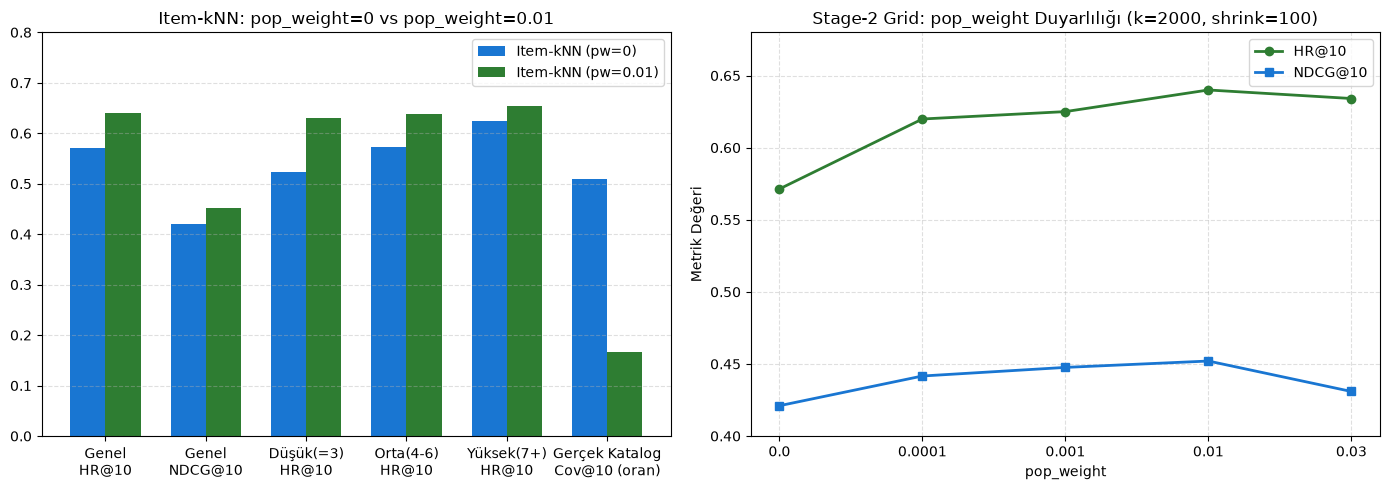

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol: pop_weight=0 vs pop_weight=0.01 (Genel, Aktivite, Katalog Coverage)
comp_labels = [
    "Genel\nHR@10",
    "Genel\nNDCG@10",
    "Düşük(=3)\nHR@10",
    "Orta(4-6)\nHR@10",
    "Yüksek(7+)\nHR@10",
    "Gerçek Katalog\nCov@10 (oran)",
]
pw0_vals = [
    eval_pw0["overall"]["hit_rate"],
    eval_pw0["overall"]["ndcg"],
    eval_pw0["activity"]["low"]["hit_rate"],
    eval_pw0["activity"]["medium"]["hit_rate"],
    eval_pw0["activity"]["high"]["hit_rate"],
    cov_pw0["catalog_cov_25610_pct"] / 100.0,
]
pw001_vals = [
    eval_pw001["overall"]["hit_rate"],
    eval_pw001["overall"]["ndcg"],
    eval_pw001["activity"]["low"]["hit_rate"],
    eval_pw001["activity"]["medium"]["hit_rate"],
    eval_pw001["activity"]["high"]["hit_rate"],
    cov_pw001["catalog_cov_25610_pct"] / 100.0,
]

x_c = np.arange(len(comp_labels))
w_c = 0.35
axes[0].bar(x_c - w_c / 2, pw0_vals, w_c, label="Item-kNN (pw=0)", color="#1976d2")
axes[0].bar(x_c + w_c / 2, pw001_vals, w_c, label="Item-kNN (pw=0.01)", color="#2e7d32")
axes[0].set_title("Item-kNN: pop_weight=0 vs pop_weight=0.01")
axes[0].set_xticks(x_c)
axes[0].set_xticklabels(comp_labels)
axes[0].set_ylim(0, 0.80)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend()

# Sağ: Stage 2 Grid'den pop_weight duyarlılığı
pw_labels = [str(v) for v in df_stage2_footnote["pop_weight"].tolist()]
x_p = np.arange(len(pw_labels))
axes[1].plot(x_p, df_stage2_footnote["hit_rate"], marker="o", linewidth=2, label="HR@10", color="#2e7d32")
axes[1].plot(x_p, df_stage2_footnote["ndcg"], marker="s", linewidth=2, label="NDCG@10", color="#1976d2")
axes[1].set_title("Stage-2 Grid: pop_weight Duyarlılığı (k=2000, shrink=100)")
axes[1].set_xticks(x_p)
axes[1].set_xticklabels(pw_labels)
axes[1].set_xlabel("pop_weight")
axes[1].set_ylabel("Metrik Değeri")
axes[1].set_ylim(0.40, 0.68)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.show()